## Introduction

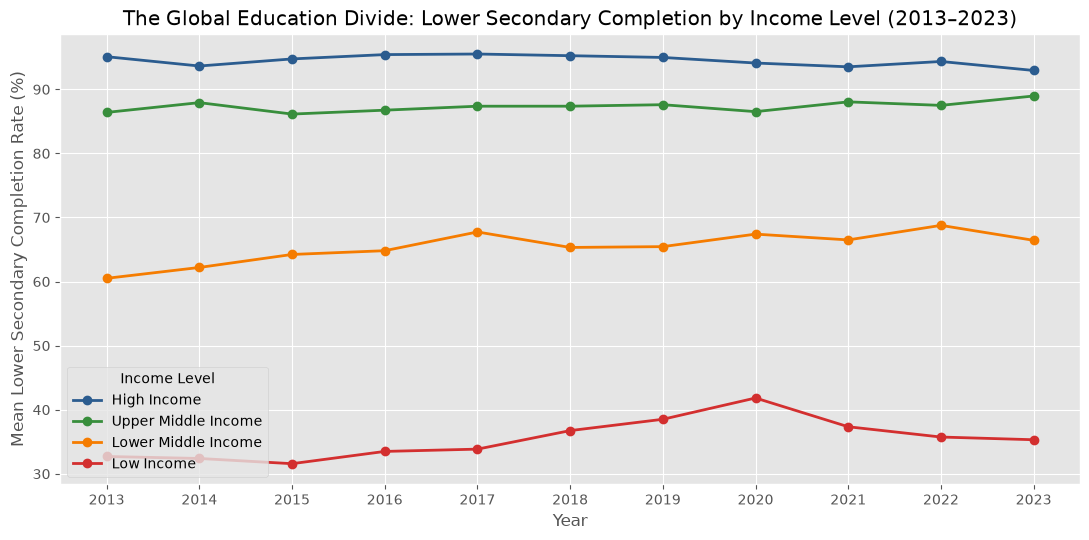

In [53]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wbgapi as wb
import os
import requests
plt.style.use('ggplot')


# baseline plot for the Introduction (using cached World Bank CSV)
df_intro = pd.read_csv('all_countries_data.csv')
df_intro['Lower_Sec_Completion_Pct'] = df_intro['Lower_Sec_Completion_Pct'].clip(upper=100.0)

income_order = ['High Income', 'Upper Middle Income', 'Lower Middle Income', 'Low Income']
income_colors = {
    'High Income': '#2b5c8f',
    'Upper Middle Income': '#388e3c',
    'Lower Middle Income': '#f57c00',
    'Low Income': '#d32f2f'
}

plt.figure(figsize=(11, 5.5))
for lvl in income_order:
    subset = df_intro[df_intro['Income_Level'] == lvl]
    yearly_edu = subset.groupby('Year')['Lower_Sec_Completion_Pct'].mean()
    plt.plot(
        yearly_edu.index, yearly_edu.values,
        marker='o', linewidth=2, color=income_colors[lvl], label=lvl
    )

plt.title('The Global Education Divide: Lower Secondary Completion by Income Level (2013–2023)')
plt.xlabel('Year')
plt.ylabel('Mean Lower Secondary Completion Rate (%)')
plt.xticks(range(2013, 2024))
plt.legend(title='Income Level')
plt.tight_layout()
plt.show()

## Datasets

In [38]:
def fetch_world_bank_data(indicators, time_range):
    print("Fetching data from World Bank API...")
    df = wb.data.DataFrame(
        series=indicators.keys(), 
        time=time_range, 
        labels=True, 
        columns='series' 
    ).reset_index()
    
    # Rename columns for clarity
    df = df.rename(columns={'economy': 'Country_Code', 'Country': 'Country_Name', 'time': 'Year'})
    df = df.rename(columns=indicators)
    df = df.drop(columns='Time', errors='ignore')
    df['Year'] = df['Year'].str.replace('YR', '').astype(int)

    df = attach_income(df)
    return df

def attach_income(df):
    #grab economic data from World bank
    countries = wb.economy.DataFrame()
    sovereign_countries = countries[countries['aggregate'] == False]
    sovereign_codes = sovereign_countries.index

    # filter to only sovereign countries
    df = df[df['Country_Code'].isin(sovereign_codes)]

    income_map = sovereign_countries['incomeLevel'].to_dict()

    # map income code onto main df
    df['Income_Level_Code'] = df['Country_Code'].map(income_map)

    # create readable mapping for income levels
    income_names = {
        'HIC': 'High Income',
        'UMC': 'Upper Middle Income',
        'LMC': 'Lower Middle Income',
        'LIC': 'Low Income',
        'INX': 'Not Classified'
    }

    #map codes to readable levels
    df['Income_Level'] = df['Income_Level_Code'].map(income_names)

    # drop not classified in order to keep analysis clean and focused on classified income levels
    df = df[df['Income_Level'] != 'Not Classified']
    return df

def fetch_imf_data(imf_indicators, time_range):
    base_url = "https://www.imf.org/external/datamapper/api/v1"
    target_years = set(map(str, time_range))
    imf_df = None

    for code, col_name in imf_indicators.items():
        url = f"{base_url}/{code}"
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        data = response.json()

        # Navigate JSON structure: values -> indicator_code -> country_code -> year
        country_dict = data.get('values', {}).get(code, {})
        records = []

        for country_code, years_data in country_dict.items():
            for year_str, value in years_data.items():
                if year_str in target_years:
                    records.append({
                        'Country_Code': country_code,
                        'Year': int(year_str),
                        col_name: pd.to_numeric(value, errors='coerce')
                    })

        df_indicator = pd.DataFrame(records)
        if imf_df is None:
            imf_df = df_indicator
        else:
            imf_df = pd.merge(imf_df, df_indicator, on=['Country_Code', 'Year'], how='outer')

    return imf_df

if (os.path.isfile('all_countries_data.csv') and os.path.isfile('imf_secondary_data.csv')):
    print('reading CSV.....')
    df_wb = pd.read_csv('all_countries_data.csv', delimiter=',')
    df_imf = pd.read_csv('imf_secondary_data.csv', delimiter=',')
    
else:
    # define the specific World Bank Series Codes
    indicators = {
        'IT.NET.USER.ZS': 'Internet_Usage_Pct',
        'SE.SEC.CMPT.LO.ZS': 'Lower_Sec_Completion_Pct',
        'NY.ADJ.NNTY.PC.CD': 'Income_Per_Capita_USD',
        'EG.ELC.ACCS.ZS': 'Electricity_Access_Pct',
    }

    imf_indicators = {
        'PCPIPCH': 'Inflation_Rate_Pct',    
        'LUR': 'Unemployment_Rate_Pct'  
    }
    
    time_range = range(2013, 2024)

    print("Fetching data API")
    df_wb = fetch_world_bank_data(indicators, time_range)
    df_imf = fetch_imf_data(imf_indicators, time_range)

    #save to csv
    df_imf.to_csv('imf_secondary_data.csv', index=False)
    df_wb.to_csv('all_countries_data.csv', index=False)

    print("\nData fetched successfully!")




Fetching data API
Fetching data from World Bank API...

Data fetched successfully!


## Data Preprocessing

In [50]:
def clean_and_merge_data(df, df_imf):
    # merge IMF data with World Bank data
    df = pd.merge(df, df_imf, on=['Country_Code', 'Year'], how='inner')
    df = df.sort_values(['Country_Code', 'Year']).reset_index(drop=True)

    print('missing values before interpolation')
    print(df.isnull().sum()[df.isnull().sum() > 0], "\n")
    wdi_cols = [
        'Lower_Sec_Completion_Pct',
        'Income_Per_Capita_USD',
        'Electricity_Access_Pct',
        'Internet_Usage_Pct'
    ]
    imf_cols = ['Inflation_Rate_Pct', 'Unemployment_Rate_Pct']  

    for col in wdi_cols + imf_cols:
        df[col] = df.groupby('Country_Code')[col].transform(lambda s: s.interpolate(method='linear').ffill().bfill())

    for col in wdi_cols:
        df[col] = df[col].fillna(df.groupby(['Income_Level', 'Year'])[col].transform('median'))
        df[col] = df[col].fillna(df.groupby('Income_Level')[col].transform('median'))

    pct_cols = ['Lower_Sec_Completion_Pct', 'Electricity_Access_Pct', 'Internet_Usage_Pct']
    df[pct_cols] = df[pct_cols].clip(upper=100.0)

    inf_95 = df['Inflation_Rate_Pct'].quantile(0.95)
    unemp_95 = df['Unemployment_Rate_Pct'].quantile(0.95)
    df.loc[df['Inflation_Rate_Pct'] >= inf_95, 'Inflation_Rate_Pct'] = np.nan
    df.loc[df['Unemployment_Rate_Pct'] >= unemp_95, 'Unemployment_Rate_Pct'] = np.nan

    # remove high values from inflation in order to avoid skewing grapgs with hyperinflation outliers
    df['Inflation_Rate_Pct'] = df.groupby('Country_Code')['Inflation_Rate_Pct'].transform(lambda s: s.interpolate(method='linear').ffill().bfill())

    print("Missing values after preprocessing (full panel):")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("Missing values after macro filtering:")

    return df

df = clean_and_merge_data(df_wb, df_imf)

missing values before interpolation
Internet_Usage_Pct           99
Income_Per_Capita_USD       551
Lower_Sec_Completion_Pct    717
Inflation_Rate_Pct            3
Unemployment_Rate_Pct       902
dtype: int64 

Missing values after preprocessing (full panel):
Inflation_Rate_Pct        11
Unemployment_Rate_Pct    936
dtype: int64
Missing values after macro filtering:


## Data Analysis

In [51]:
income_order = ['High Income', 'Upper Middle Income', 'Lower Middle Income', 'Low Income']


df_country = (df.groupby(['Country_Code', 'Country_Name', 'Income_Level'], as_index=False).mean(numeric_only=True))

def summarize_by_income(df, value_col):
    return (df.groupby('Income_Level')[value_col].agg(['count', 'mean', 'std', 'median']).reindex(income_order)).round(2)

def progress_per_year(data):
    """Compare 2013 vs 2023 means and 10-year change (+pp) per Income Level."""
    cols = ['Lower_Sec_Completion_Pct', 'Internet_Usage_Pct', 'Electricity_Access_Pct']
    d_2013 = data[data['Year'] == 2013].groupby('Income_Level')[cols].mean().reindex(income_order)
    d_2023 = data[data['Year'] == 2023].groupby('Income_Level')[cols].mean().reindex(income_order)

    progress = pd.DataFrame({
        'Edu_2013 (%)': d_2013['Lower_Sec_Completion_Pct'],
        'Edu_2023 (%)': d_2023['Lower_Sec_Completion_Pct'],
        'Edu_Change (+pp)': d_2023['Lower_Sec_Completion_Pct'] - d_2013['Lower_Sec_Completion_Pct'],
        'Internet_2013 (%)': d_2013['Internet_Usage_Pct'],
        'Internet_2023 (%)': d_2023['Internet_Usage_Pct'],
        'Internet_Change (+pp)': d_2023['Internet_Usage_Pct'] - d_2013['Internet_Usage_Pct'],
        'Elec_2013 (%)': d_2013['Electricity_Access_Pct'],
        'Elec_2023 (%)': d_2023['Electricity_Access_Pct'],
        'Elec_Change (+pp)': d_2023['Electricity_Access_Pct'] - d_2013['Electricity_Access_Pct']
    }).round(2)
    return progress

def compare_low_income_internet_tiers(data_country):
    """Split Low Income countries at median internet usage and compare outcomes."""
    low_inc = data_country[data_country['Income_Level'] == 'Low Income'].copy()
    med_net = low_inc['Internet_Usage_Pct'].median()
    low_inc['Internet_Tier'] = np.where(
        low_inc['Internet_Usage_Pct'] >= med_net,
        f'Above Median Internet (>= {med_net:.1f}%)',
        f'Below Median Internet (< {med_net:.1f}%)'
    )
    cols = ['Internet_Usage_Pct', 'Electricity_Access_Pct', 'Lower_Sec_Completion_Pct', 'Income_Per_Capita_USD']
    return low_inc.groupby('Internet_Tier')[cols].mean().round(2)

def compare_inflation_regimes(data_country):
    """Compare education & internet outcomes for High vs Low inflation within income tiers."""
    sub = data_country.dropna(subset=['Inflation_Rate_Pct']).copy()
    med_inf = sub['Inflation_Rate_Pct'].median()
    sub['Inflation_Regime'] = np.where(
        sub['Inflation_Rate_Pct'] >= med_inf,
        'High Inflation (>= Median)',
        'Low Inflation (< Median)'
    )
    return (
        sub.groupby(['Income_Level', 'Inflation_Regime'])[['Lower_Sec_Completion_Pct', 'Internet_Usage_Pct']]
        .mean()
        .unstack()
        .reindex(income_order)
        .round(2)
    )

main_indicators = [
    'Income_Per_Capita_USD',
    'Lower_Sec_Completion_Pct',
    'Internet_Usage_Pct',
    'Inflation_Rate_Pct',
    'Unemployment_Rate_Pct' 
]

decade_df = progress_per_year(df_country)
low_income_internet_tiers_df = compare_low_income_internet_tiers(df_country)
display(summarize_by_income(df_country, main_indicators))
display(decade_df)
display(low_income_internet_tiers_df)
display(compare_inflation_regimes(df_country))

Income_Per_Capita_USD                                \
                                    count      mean       std    median   
Income_Level                                                              
High Income                            67  27769.74  15091.60  24143.58   
Upper Middle Income                    57   5089.95   1726.48   4709.83   
Lower Middle Income                    46   2026.79   1700.90   1667.54   
Low Income                             23    540.22    214.00    529.54   

                    Lower_Sec_Completion_Pct                       \
                                       count   mean    std median   
Income_Level                                                        
High Income                               67  94.32   8.01  97.20   
Upper Middle Income                       57  86.12  13.75  89.76   
Lower Middle Income                       46  63.10  18.23  63.40   
Low Income                                23  34.78  13.19  33.06   

                    Internet_Usage_Pct                       \
                                 count   mean    std median   
Income_Level                                                  
High Income                         67  83.13  10.10  84.00   
Upper Middle Income                 57  57.82  14.55  60.69   
Lower Middle Income                 46  34.97  16.11  30.31   
Low Income                          23  12.49   6.25  11.43   

                    Inflation_Rate_Pct                     \
                                 count  mean   std median   
Income_Level                                                
High Income                         67  2.41  1.35   2.25   
Upper Middle Income                 57  4.35  3.18   3.62   
Lower Middle Income                 45  5.63  3.43   5.00   
Low Income                          23  6.49  5.64   5.38   

                    Unemployment_Rate_Pct                      
                                    count   mean   std median  
Income_Level                                                   
High Income                            58   6.53  2.97   6.13  
Upper Middle Income                    38   8.53  4.21   7.72  
Lower Middle Income                    15   8.41  3.49   7.30  
Low Income                              1  15.20   NaN  15.20

,Edu_2013 (%),Edu_2023 (%),Edu_Change (+pp),Internet_2013 (%),Internet_2023 (%),Internet_Change (+pp),Elec_2013 (%),Elec_2023 (%),Elec_Change (+pp)
Income_Level,,,,,,,,,
High Income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Upper Middle Income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lower Middle Income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Low Income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Internet_Usage_Pct,Electricity_Access_Pct,Lower_Sec_Completion_Pct,Income_Per_Capita_USD
Internet_Tier,,,,
Above Median Internet (>= 11.4%),17.02,43.58,40.01,611.50
Below Median Internet (< 11.4%),7.54,22.62,29.09,462.47


Lower_Sec_Completion_Pct                           \
Inflation_Regime    High Inflation (>= Median) Low Inflation (< Median)   
Income_Level                                                              
High Income                              92.41                    94.92   
Upper Middle Income                      86.70                    85.25   
Lower Middle Income                      65.19                    57.36   
Low Income                               37.06                    29.59   

                            Internet_Usage_Pct                           
Inflation_Regime    High Inflation (>= Median) Low Inflation (< Median)  
Income_Level                                                             
High Income                              81.28                    83.71  
Upper Middle Income                      58.84                    56.32  
Lower Middle Income                      33.08                    37.18  
Low Income                               13.41                    10.39

## Visualization

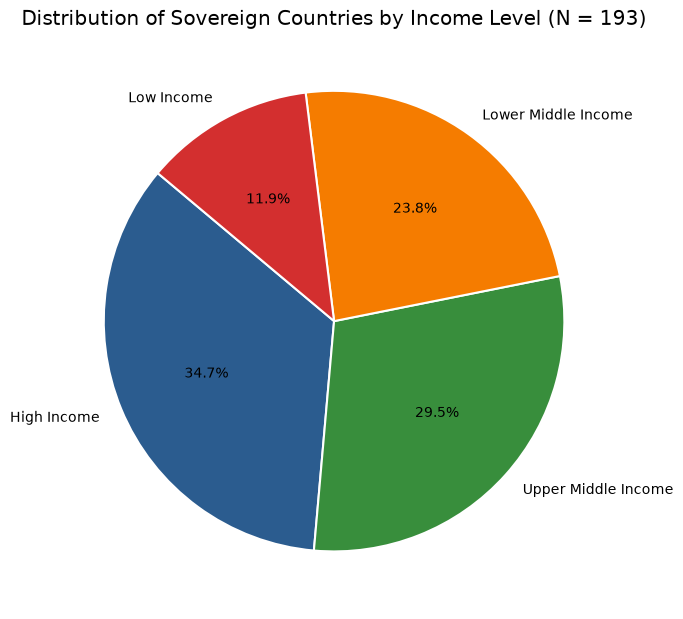

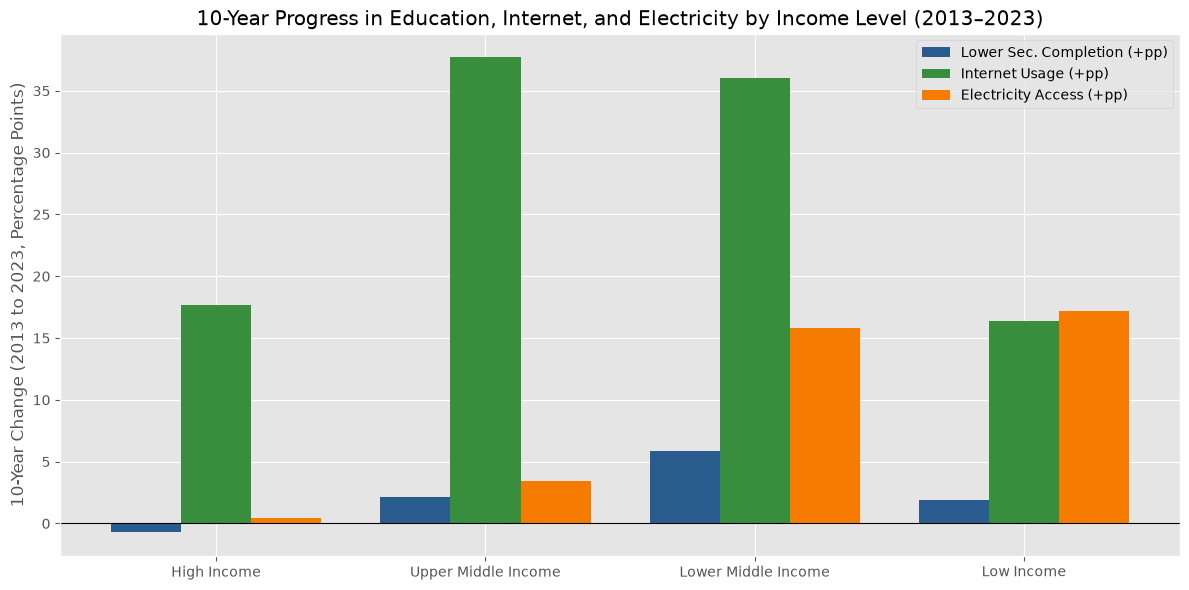

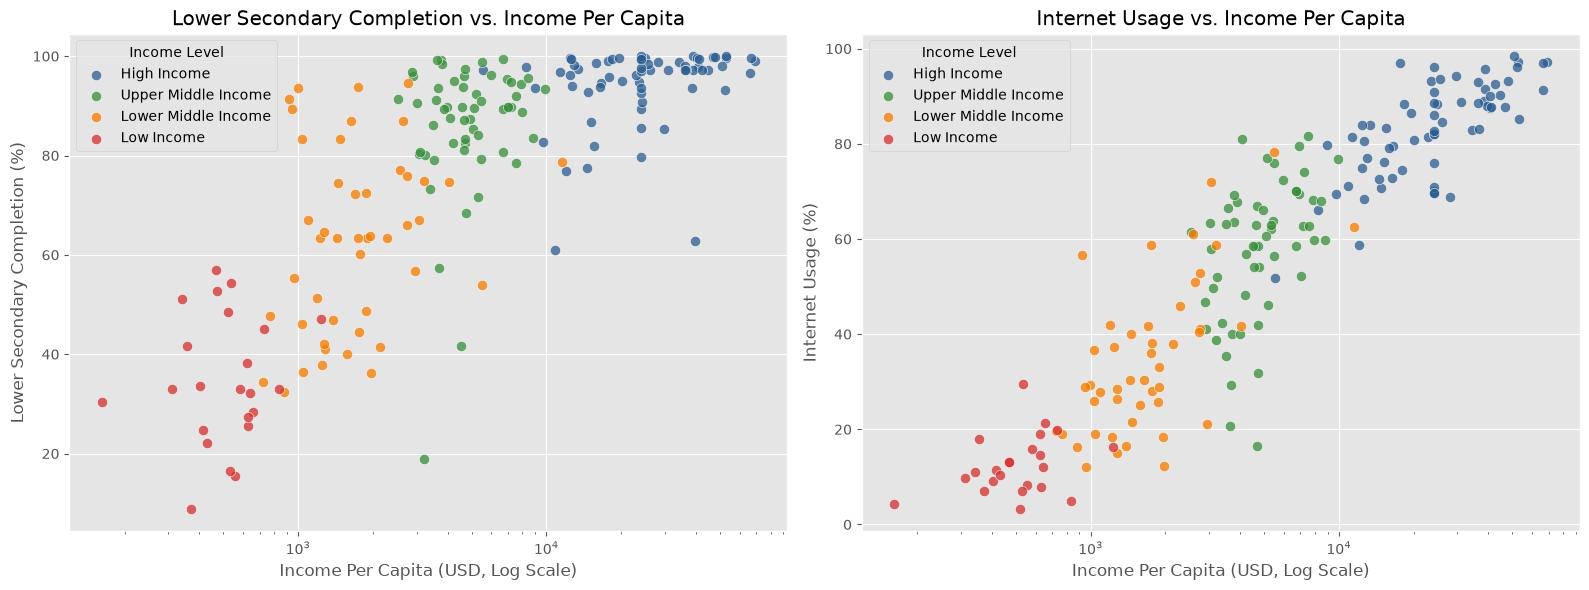

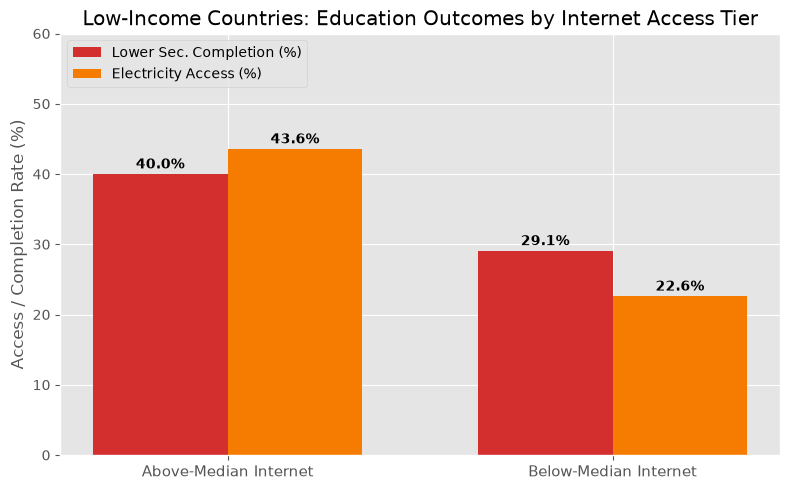

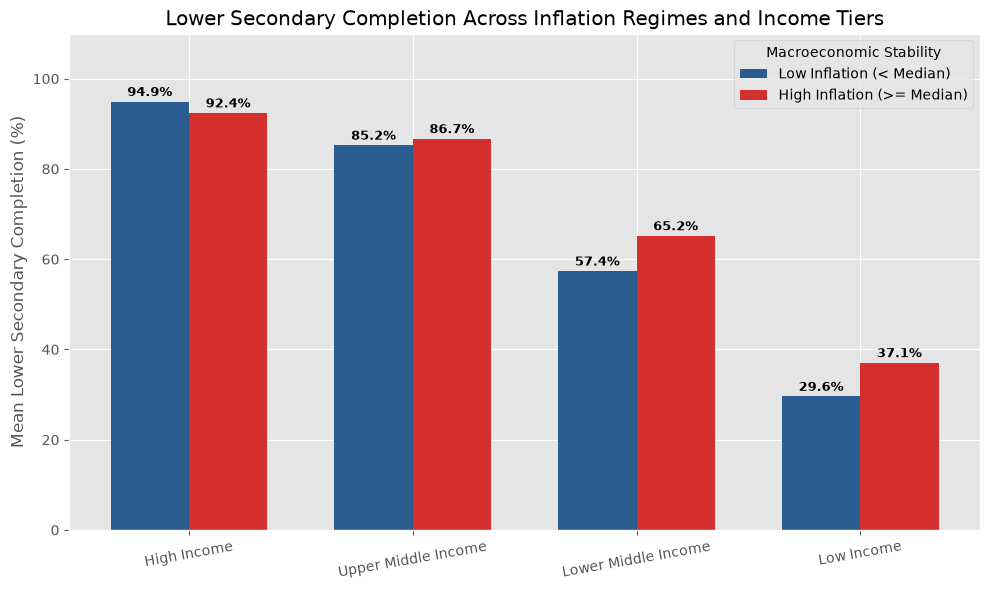

In [ ]:
income_colors = {
    'High Income': '#2b5c8f',
    'Upper Middle Income': '#388e3c',
    'Lower Middle Income': '#f57c00',
    'Low Income': '#d32f2f'
}

#pie chart of how many countries are in each income level
counts = df_country['Income_Level'].value_counts().reindex(income_order)
plt.figure(figsize=(7, 7))
plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[income_colors[lvl] for lvl in counts.index],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title(f'Distribution of Sovereign Countries by Income Level (N = {counts.sum()})')
plt.tight_layout()
plt.show()

# (2013 vs. 2023)
metrics = {
    'Edu': 'Lower_Sec_Completion_Pct',
    'Internet': 'Internet_Usage_Pct',
    'Elec': 'Electricity_Access_Pct'
}

# Use the year-level dataset, not df_country, which contains mostly 2018 averages.
period_df = df[df['Year'].isin([2013, 2023])].copy()

# Calculate income-level means for each endpoint year.
summary = (
    period_df
    .groupby(['Income_Level', 'Year'])[list(metrics.values())]
    .mean()
    .unstack('Year')
    .reindex(income_order)
)

decade_df = pd.DataFrame(index=income_order)

for name, column in metrics.items():
    decade_df[f'{name}_Change (+pp)'] = (
        summary[(column, 2023)] - summary[(column, 2013)]
    )

x_idx = np.arange(len(income_order))
width = 0.26

plt.figure(figsize=(12, 6))
plt.bar(
    x_idx - width,
    decade_df['Edu_Change (+pp)'],
    width,
    label='Lower Sec. Completion (+pp)',
    color='#2b5c8f'
)
plt.bar(
    x_idx,
    decade_df['Internet_Change (+pp)'],
    width,
    label='Internet Usage (+pp)',
    color='#388e3c'
)
plt.bar(
    x_idx + width,
    decade_df['Elec_Change (+pp)'],
    width,
    label='Electricity Access (+pp)',
    color='#f57c00'
)

plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(x_idx, income_order)
plt.ylabel('10-Year Change (2013 to 2023, Percentage Points)')
plt.title('10-Year Progress in Education, Internet, and Electricity by Income Level (2013–2023)')
plt.legend()
plt.tight_layout()
plt.show()

#  Education & Internet vs. Income Per Capita
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
scatter_metrics = [
    ('Lower_Sec_Completion_Pct', 'Lower Secondary Completion (%)', 'Lower Secondary Completion vs. Income Per Capita'),
    ('Internet_Usage_Pct', 'Internet Usage (%)', 'Internet Usage vs. Income Per Capita')
]
for ax, (y_col, ylabel, title) in zip(axes, scatter_metrics):
    for lvl in income_order:
        subset = df_country[df_country['Income_Level'] == lvl]
        ax.scatter(
            subset['Income_Per_Capita_USD'], subset[y_col],
            label=lvl, color=income_colors[lvl], alpha=0.75, s=55, edgecolors='w'
        )
    ax.set_xscale('log')
    ax.set_title(title)
    ax.set_xlabel('Income Per Capita (USD, Log Scale)')
    ax.set_ylabel(ylabel)
    ax.legend(title='Income Level')
plt.tight_layout()
plt.show()

# low income Internet Tier Comparison Bar Chart
low_inc = df_country[df_country['Income_Level'] == 'Low Income'].copy()
med_net = low_inc['Internet_Usage_Pct'].median()
low_inc['Internet_Tier'] = np.where(
    low_inc['Internet_Usage_Pct'] >= med_net,
    'Above-Median Internet',
    'Below-Median Internet'
)

tier_summary = low_inc.groupby('Internet_Tier')[['Lower_Sec_Completion_Pct', 'Electricity_Access_Pct']].mean()

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(tier_summary.index))
width = 0.35

bars1 = ax.bar(x - width/2, tier_summary['Lower_Sec_Completion_Pct'], width, label='Lower Sec. Completion (%)', color='#d32f2f')
bars2 = ax.bar(x + width/2, tier_summary['Electricity_Access_Pct'], width, label='Electricity Access (%)', color='#f57c00')

ax.set_xticks(x)
ax.set_xticklabels(tier_summary.index, fontsize=11)
ax.set_ylabel('Access / Completion Rate (%)')
ax.set_ylim(0, 60)
ax.set_title('Low-Income Countries: Education Outcomes by Internet Access Tier')
ax.legend(loc='upper left')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords='offset points', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# inflation stability bar vhart (High vs Low Inflation by Income Tier)
sub_inf = df_country.dropna(subset=['Inflation_Rate_Pct']).copy()
med_inf = sub_inf['Inflation_Rate_Pct'].median()
sub_inf['Inflation_Regime'] = np.where(
    sub_inf['Inflation_Rate_Pct'] >= med_inf,
    'High Inflation',
    'Low Inflation'
)

macro_bar_data = (
    sub_inf.groupby(['Income_Level', 'Inflation_Regime'])['Lower_Sec_Completion_Pct']
    .mean()
    .unstack()
    .reindex(income_order)
)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(income_order))
width = 0.35

bars1 = ax.bar(x - width/2, macro_bar_data['Low Inflation'], width, label='Low Inflation (< Median)', color='#2b5c8f')
bars2 = ax.bar(x + width/2, macro_bar_data['High Inflation'], width, label='High Inflation (>= Median)', color='#d32f2f')

ax.set_xticks(x)
ax.set_xticklabels(income_order, rotation=10, fontsize=10)
ax.set_ylabel('Mean Lower Secondary Completion (%)')
ax.set_ylim(0, 110)
ax.set_title('Lower Secondary Completion Across Inflation Regimes and Income Tiers')
ax.legend(title='Macroeconomic Stability')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()
  

## Discussion

## Conclusion

## Reflection

## AI Use statement